Total noisy signals: 108
result rows: 26676
       windows_id  variant noise_type  noise_strength  window_start  \
0  signal_0_0.3_0        0     random             0.3             0   
1  signal_0_0.3_0        0     random             0.3             0   
2  signal_0_0.3_0        0     random             0.3             0   
3  signal_0_0.3_0        0     random             0.3             0   
4  signal_0_0.3_0        0     random             0.3             0   

   window_mean  window_std  window_range  window_slope  window_roughness  ...  \
0    10.260524    0.232364      1.227805     -0.001117          0.423296  ...   
1    10.260524    0.232364      1.227805     -0.001117          0.423296  ...   
2    10.260524    0.232364      1.227805     -0.001117          0.423296  ...   
3    10.260524    0.232364      1.227805     -0.001117          0.423296  ...   
4    10.260524    0.232364      1.227805     -0.001117          0.423296  ...   

  filter_window  polyorder  cutoff  filter

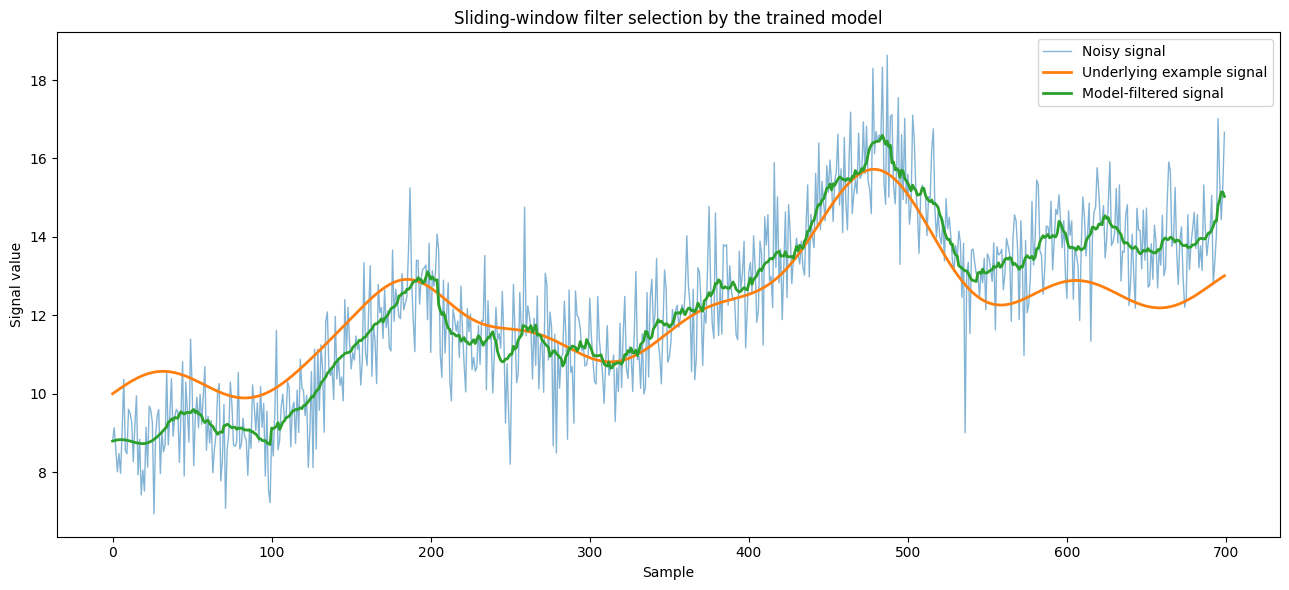

Filter chosen for each window:
Samples 0-99: Butterworth (cutoff=0.05, order=3)
Samples 35-134: Moving Average (window=15)
Samples 70-169: Butterworth (cutoff=0.05, order=2)
Samples 105-204: Butterworth (cutoff=0.05, order=2)
Samples 140-239: Moving Average (window=15)
Samples 175-274: Moving Average (window=15)
Samples 210-309: Moving Average (window=15)
Samples 245-344: Moving Average (window=15)
Samples 280-379: Moving Average (window=15)
Samples 315-414: Moving Average (window=15)
Samples 350-449: Moving Average (window=15)
Samples 385-484: Moving Average (window=15)
Samples 420-519: Moving Average (window=15)
Samples 455-554: Median Filter (window=15)
Samples 490-589: Moving Average (window=15)
Samples 525-624: Moving Average (window=15)
Samples 560-659: Moving Average (window=15)
Samples 595-694: Butterworth (cutoff=0.05, order=3)
Samples 600-699: Moving Average (window=15)


In [4]:
#Requirements

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import joblib

from sklearn.ensemble import RandomForestClassifier  #### NEW: The model predicts a filter category, not a numerical score.
from sklearn.model_selection import GroupShuffleSplit
from scipy.ndimage import median_filter, uniform_filter1d
from scipy.signal import savgol_filter, butter, sosfiltfilt, detrend

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import  StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report  #### NEW: Classification performance metrics.



#"Random common shapes with noise - data generation"

rng = np.random.default_rng(42)


def generate_clean_signal(variant, length_per_section=100):

    n = length_per_section
    offset = rng.uniform(-0.5, 0.5)

    # Flat signal
    flat = np.full(n, 10 + offset)

    # Trend signal
    x = np.arange(n)
    trend = 10 + offset + 0.04 * x

    # Peak
    center = n / 2 + rng.uniform(-8, 8)
    width = rng.uniform(12, 18)
    peak = (
        14 + offset
        + 4 * np.exp(-0.5 * ((x - center) / width) ** 2)
    )

    # Change in the signal level - Step
    step = np.full(n, 14 + offset)
    step[n // 2:] = 18 + offset

    # Flat signal but at a different level
    flat_new = np.full(n, 18 + offset)

    return np.concatenate([flat, trend, peak, step, flat_new])

#Lets add noise to the clean signal of 3 different types:
def add_noise(clean_signal, noise_type, strength):

    if noise_type == "random":
        noise = rng.normal(0, strength, len(clean_signal))

    elif noise_type == "spikes":
        noise = rng.normal(0, 0.15 * strength, len(clean_signal))

        spike_count = max(1, int(len(clean_signal) * 0.04))
        positions = rng.choice(
            len(clean_signal), size=spike_count, replace=False
        )
        noise[positions] += rng.choice(
            [-1, 1], size=spike_count
        ) * 4 * strength

    elif noise_type == "drift":
        # Gradual change in the noise level across the signal.
        drift = np.linspace(
            -2 * strength, 2 * strength, len(clean_signal)
        )
        noise = drift + rng.normal(
            0, 0.15 * strength, len(clean_signal)
        )

    else:
        raise ValueError("Unknown noise type")

    return clean_signal + noise


# 2. Generate full mixed-signal variants with noise

generated_signals = []

noise_types = ["random", "spikes", "drift"]
noise_strengths = [0.3, 0.7, 1.2]

for variant in range(12):

    # Generate one full signal containing all five sections
    clean_signal = generate_clean_signal(variant)

    # Create noisy versions of this signal
    for noise_type in noise_types:
        for strength in noise_strengths:

            noisy_signal = add_noise(
                clean_signal,
                noise_type,
                strength
            )

            # Store everything needed for windowing and filter testing
            generated_signals.append({
                "variant": variant,
                "noise_type": noise_type,
                "noise_strength": strength,
                "clean_signal": clean_signal.copy(),
                "noisy_signal": noisy_signal
            })

print("Total noisy signals:", len(generated_signals))



#Sliding window features
#the window configuration is adjsutable by changing the window size and overlapping step size!
WINDOW_SIZE = 100
STEP_SIZE = 35


def get_window_starts(signal_length):


    starts = list(
        range(0, signal_length - WINDOW_SIZE + 1, STEP_SIZE)
    )

    #last window must be included if otherwise does not fulfill the selection range criteria!!
    final_start = signal_length - WINDOW_SIZE
    if starts[-1] != final_start:
        starts.append(final_start)

    return starts
# Creating Filters with their different settings to be applied

Filter_Config = []

#Median Filter
for size in [5,10,15]:
  Filter_Config.append({
      "name": "Median Filter",
      "filter_window": size,
      "polyorder": np.nan,
      "cutoff": np.nan,
      "filter_order": np.nan })

#Moving Average Filter
for size in [5,10,15]:
  Filter_Config.append({
      "name": "Moving Average",
      "filter_window": size,
      "polyorder": np.nan,
      "cutoff": np.nan,
      "filter_order": np.nan })

#Sav_gol Filter
for size in [5,10,15]:
  for order in [2,3]:
    Filter_Config.append({
        "name": "Savitzky-Golay",
        "filter_window": size,
        "polyorder": order,
        "cutoff": np.nan,
        "filter_order": np.nan })

#Butterworth Filter

for cutoff in [0.05, 0.1, 0.2]:
  for order in [2,3]:
    Filter_Config.append({
        "name": "Butterworth",
        "filter_window": np.nan,
        "polyorder": np.nan,
        "cutoff": cutoff,
        "filter_order": order })

#linear detrending Filter

Filter_Config.append({
    "name": "Linear Detrending",
    "filter_window": np.nan,
    "polyorder": np.nan,
    "cutoff": np.nan,
    "filter_order": np.nan })
#Lets apply the filters in a loop with different settings and defined configurations!


def apply_filters(signal, filter_config):

  name = filter_config ["name"]

  if name == "Median Filter":
    return median_filter (signal, size= int(filter_config["filter_window"]))

  elif name == "Moving Average":
    return uniform_filter1d(signal,size = int(filter_config["filter_window"]))

  elif name == "Savitzky-Golay":
    return savgol_filter(signal, window_length=int(filter_config["filter_window"]), polyorder=int(filter_config["polyorder"]))

  elif name == "Butterworth":
    sos = butter(int(filter_config["filter_order"]), filter_config["cutoff"], btype='low', output='sos')
    return sosfiltfilt (sos, signal)

  elif name == "Linear Detrending":
    return detrend(signal)

  else:
    raise ValueError("Unknown filter name")

# Apply every filter to every window and record performance

results = []

for signal_data in generated_signals:

    clean_signal = signal_data["clean_signal"]
    noisy_signal = signal_data["noisy_signal"]


    window_starts = get_window_starts(len(noisy_signal))

    for start in window_starts:

        end = start + WINDOW_SIZE

        noisy_window = noisy_signal[start:end]
        clean_window = clean_signal[start:end]


        for filter_config in Filter_Config: #which is defined earlier

            filtered_window = apply_filters(
                noisy_window, filter_config
            )


            errors = filtered_window - clean_window

            rmse = np.sqrt(np.mean(errors ** 2))
            mae = np.mean(np.abs(errors))

            #### NEW: Calculate SNR in decibels, following the paper's approach.
            #### Compare the clean window with the filtered window.
            signal_power = np.sum(clean_window ** 2)
            error_power = np.sum(errors ** 2)

            if error_power > 0:
                snr = 10 * np.log10(signal_power / error_power)
            else:
                snr = np.inf  # Perfect reconstruction: no remaining error.


            results.append({
                "variant": signal_data["variant"],
                "noise_type": signal_data["noise_type"],
                "noise_strength": signal_data["noise_strength"],
                "window_start": start,

                "window_mean": np.mean(noisy_window),
                "window_std": np.std(noisy_window),
                "window_range": np.ptp(noisy_window), #Peak to Peak range
                "window_slope": np.polyfit(
                    np.arange(len(noisy_window)),
                    noisy_window,
                    1
                )[0], #Slope information for the model to see how the selected window is behaving (increasing or decreasing etc)
                "window_roughness": np.mean(
                    np.abs(np.diff(noisy_window, n=2))
                ), #Roughness values need to tell the changes (abrupt or smooth) so model will learn the pattern of the change and corresponding filters etc information
                "filter_name": filter_config["name"],
                "filter_window": filter_config["filter_window"],
                "polyorder": filter_config["polyorder"],
                "cutoff": filter_config["cutoff"],
                "filter_order": filter_config["filter_order"],

                "RMSE": rmse,
                "MAE": mae,

                #### NEW: Store the SNR result for each filter configuration.
                "SNR": snr
            })


results_df = pd.DataFrame(results)



#### NEW: Identify the best filter configuration for each window.

best_rows = results_df.loc[
    results_df.groupby(
        ["variant", "noise_type", "noise_strength", "window_start"]
    )["SNR"].idxmax()
].copy()

#### NEW: Format settings consistently (for example, 5 and 5.0 both become "5").
def category_value(value):
    if pd.isna(value):
        return "nan"
    if isinstance(value, (int, float, np.integer, np.floating)) and float(value).is_integer():
        return str(int(value))
    return str(value)


#### NEW: Create a category label containing the winning filter and its settings.
best_rows["best_filter"] = best_rows.apply(
    lambda row: "_".join([
        category_value(row["filter_name"]),
        category_value(row["filter_window"]),
        category_value(row["polyorder"]),
        category_value(row["cutoff"]),
        category_value(row["filter_order"])
    ]),
    axis=1
)

#### NEW: Add the winning category to every candidate row belonging to that window.
results_df = results_df.merge(
    best_rows[
        ["variant", "noise_type", "noise_strength", "window_start", "best_filter"]
    ],
    on=["variant", "noise_type", "noise_strength", "window_start"],
    how="left"
)

results_df.insert(0, "windows_id", "signal_" + results_df["variant"].astype(str)+ "_" +results_df["noise_strength"].astype(str)+ "_" + results_df["window_start"].astype(str))

results_df.to_csv("filter_results.csv", index=False)


#grouping and defining the min max rmse to define scoring later

window_groups = results_df.groupby(
    ["variant", "noise_type", "noise_strength", "window_start"]
)["RMSE"]

min_error = window_groups.transform("min")
max_error = window_groups.transform("max")

error_range = max_error - min_error

performance_score =  np.where(
    error_range > 0,
    100 * (max_error - results_df["RMSE"]) / error_range,
    100
)
results_df ["performance_score"]= performance_score


results_df["NRMSE"] = results_df["RMSE"] / results_df["window_range"]

#### NEW: SNR is now available to identify the best filter for each window.
#### The highest SNR represents the lowest remaining error relative to the clean signal.

results_df.to_csv("filter_results.csv", index=False)
print("result rows:", len(results_df))
print(results_df.head())

#### NEW: Make one training row per window.
#### The full filter_results.csv still keeps every filter result.
#### classifier_data.csv avoids repeating the same window once per candidate filter.

window_features = results_df.groupby(
    ["variant", "noise_type", "noise_strength", "window_start"]
)[
    ["window_mean", "window_std", "window_range",
     "window_slope", "window_roughness"]
].first()

window_labels = results_df.groupby(
    ["variant", "noise_type", "noise_strength", "window_start"]
)["best_filter"].first()

classifier_df = window_features.join(window_labels).reset_index()
classifier_df.to_csv("classifier_data.csv", index=False)  #### NEW: Save one row per window for classifier training.


# lets split the classification data for training and testing
#### NEW: Split by signal variant so windows from the same generated signal do not appear in both sets.

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.30, random_state=42
)

split_results = splitter.split(
    classifier_df,
    groups=classifier_df["variant"]
)

train_part, test_part = next(split_results)

train_df = classifier_df.iloc[train_part].copy()
test_df = classifier_df.iloc[test_part].copy()

train_df.to_csv("train.csv", index=False)
test_df.to_csv("test.csv", index=False)


# preparing the classifier and its data

#### NEW: The classifier uses only signal-window features.
#### It does not receive filter settings, because it must choose those settings.

feature_columns = [
    "window_mean",
    "window_std",
    "window_range",
    "window_slope",
    "window_roughness"
]

X_train = train_df[feature_columns]
y_train = train_df["best_filter"]

X_test = test_df[feature_columns]
y_test = test_df["best_filter"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numbers", SimpleImputer(strategy="median"), feature_columns)
    ]
)

#### NEW: RandomForestClassifier predicts the best_filter category directly.
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=1
    ))
])

model.fit(X_train, y_train)
print("Training complete")

#### NEW: Predict filter categories and check how often the model chooses the correct category.
train_df["predicted_filter"] = model.predict(X_train)
test_df["predicted_filter"] = model.predict(X_test)

print("\n" + "=" * 55)
print("TRAINING PERFORMANCE")
print("=" * 55)
print("Training windows:", len(train_df))
print("Training accuracy:", accuracy_score(y_train, train_df["predicted_filter"]))

print("\n" + "=" * 55)
print("TEST PERFORMANCE")
print("=" * 55)
print("Test windows:", len(test_df))
print("Test accuracy:", accuracy_score(y_test, test_df["predicted_filter"]))
print("\nClassification report:")
print(classification_report(y_test, test_df["predicted_filter"], zero_division=0))

#### NEW: Save the classifier and the feature-column names needed when using it later.
joblib.dump({
    "model": model,
    "feature_columns": feature_columns
}, "Signal_processing_classifier.joblib")


# ============================================================
# 1. LOAD THE TRAINED MODEL
# ============================================================

saved_model = joblib.load("Signal_processing_classifier.joblib")
model = saved_model ["model"]
feature_columns = saved_model["feature_columns"]

# These must match the window settings used when training.
WINDOW_SIZE = 100
STEP_SIZE = 35

# ============================================================
# 2. CREATE ONE REALISTIC-LOOKING EXAMPLE SIGNAL
# ============================================================

rng = np.random.default_rng(7)  # Makes this example repeatable.
time = np.arange(700)

# A slowly changing baseline with broad peaks and a small oscillation.
clean_signal = (
    10
    + 0.004 * time
    + 2.5 * np.exp(-0.5 * ((time - 190) / 28) ** 2)
    + 3.5 * np.exp(-0.5 * ((time - 470) / 42) ** 2)
    + 0.45 * np.sin(2 * np.pi * time / 115)
)

# Add measurement noise plus a gradual sensor-baseline drift.
noise = rng.normal(0, 1, len(time))
drift = np.linspace(-1.2, 1.6, len(time))
noisy_signal = clean_signal + noise + drift

# Add a few occasional spikes, as can happen in sensor measurements.
spike_positions = rng.choice(len(time), size=8, replace=False)
noisy_signal[spike_positions] += rng.choice([-1, 1], size=8) * rng.uniform(2, 3.5, size=8)

# ============================================================
# 3. DEFINE THE SAME FILTER CONFIGURATIONS USED IN TRAINING
# ============================================================

#### NEW: These configurations must match the configurations used to create the training categories.
FILTER_CONFIGS = []

for size in [5, 10, 15]:
    FILTER_CONFIGS.append({"filter_name": "Median Filter", "filter_window": size,
                           "polyorder": np.nan, "cutoff": np.nan, "filter_order": np.nan})

for size in [5, 10, 15]:
    FILTER_CONFIGS.append({"filter_name": "Moving Average", "filter_window": size,
                           "polyorder": np.nan, "cutoff": np.nan, "filter_order": np.nan})

for size in [5, 10, 15]:
    for order in [2, 3]:
        FILTER_CONFIGS.append({"filter_name": "Savitzky-Golay", "filter_window": size,
                               "polyorder": order, "cutoff": np.nan, "filter_order": np.nan})

for cutoff in [0.05, 0.1, 0.2]:
    for order in [2, 3]:
        FILTER_CONFIGS.append({"filter_name": "Butterworth", "filter_window": np.nan,
                               "polyorder": np.nan, "cutoff": cutoff, "filter_order": order})

FILTER_CONFIGS.append({"filter_name": "Linear Detrending", "filter_window": np.nan,
                       "polyorder": np.nan, "cutoff": np.nan, "filter_order": np.nan})


#### NEW: Build the same category text used in the training data.
def get_filter_category(config):
    return "_".join([
        category_value(config["filter_name"]),
        category_value(config["filter_window"]),
        category_value(config["polyorder"]),
        category_value(config["cutoff"]),
        category_value(config["filter_order"])
    ])


def apply_filter(signal, config):
    """Apply one candidate filter to a window."""
    name = config["filter_name"]

    if name == "Median Filter":  #### NEW: Use the same filter name as in training.
        return median_filter(signal, size=int(config["filter_window"]))
    elif name == "Moving Average":
        return uniform_filter1d(signal, size=int(config["filter_window"]))
    elif name == "Savitzky-Golay":
        return savgol_filter(signal, window_length=int(config["filter_window"]),
                             polyorder=int(config["polyorder"]))
    elif name == "Butterworth":
        sos = butter(int(config["filter_order"]), config["cutoff"],
                     btype="low", output="sos")
        return sosfiltfilt(sos, signal)
    elif name == "Linear Detrending":
        return detrend(signal, type="linear") + np.mean(signal)

    raise ValueError("Unknown filter")

# ============================================================
# 4. SLIDE THROUGH THE SIGNAL AND LET THE MODEL CHOOSE A FILTER
# ============================================================

starts = list(range(0, len(noisy_signal) - WINDOW_SIZE + 1, STEP_SIZE))
final_start = len(noisy_signal) - WINDOW_SIZE
if starts[-1] != final_start:
    starts.append(final_start)

# Overlapping windows are combined by averaging their filtered values.
filtered_total = np.zeros(len(noisy_signal))
coverage = np.zeros(len(noisy_signal))
selected_filters = []

for start in starts:
    end = start + WINDOW_SIZE
    noisy_window = noisy_signal[start:end]

    # These are the same signal features the model saw during training.
    window_features = {
        "window_mean": np.mean(noisy_window),
        "window_std": np.std(noisy_window),
        "window_range": np.ptp(noisy_window),
        "window_slope": np.polyfit(np.arange(WINDOW_SIZE), noisy_window, 1)[0],
        "window_roughness": np.std(np.diff(noisy_window)),
    }

    #### NEW: The classifier predicts the winning filter category directly from this window.
    window_df = pd.DataFrame([window_features])
    predicted_category = model.predict(window_df[feature_columns])[0]

    #### NEW: Find the matching filter configuration and apply it to this window.
    matching_configs = [
        config for config in FILTER_CONFIGS
        if get_filter_category(config) == predicted_category
    ]

    if not matching_configs:
        raise ValueError(f"No filter configuration found for category: {predicted_category}")

    best_config = matching_configs[0]
    filtered_window = apply_filter(noisy_window, best_config)

    filtered_total[start:end] += filtered_window
    coverage[start:end] += 1
    selected_filters.append((start, best_config["filter_name"], best_config["filter_window"],
                             best_config["cutoff"], best_config["filter_order"]))

filtered_signal = filtered_total / coverage

# ============================================================
# 5. PLOT THE SIGNALS (NO EVALUATION OR SCORES)
# ============================================================

plt.figure(figsize=(13, 6))
plt.plot(time, noisy_signal, label="Noisy signal", alpha=0.55, linewidth=1)
plt.plot(time, clean_signal, label="Underlying example signal", linewidth=2)
plt.plot(time, filtered_signal, label="Model-filtered signal", linewidth=2)
plt.xlabel("Sample")
plt.ylabel("Signal value")
plt.title("Sliding-window filter selection by the trained model")
plt.legend()
plt.tight_layout()
plt.show()

# Optional: show which filter family the model chose in each window.
print("Filter chosen for each window:")
for start, name, size, cutoff, order in selected_filters:
    settings = []
    if pd.notna(size):
        settings.append(f"window={int(size)}")
    if pd.notna(cutoff):
        settings.append(f"cutoff={cutoff}")
    if pd.notna(order):
        settings.append(f"order={int(order)}")
    extra = ", ".join(settings)
    print(f"Samples {start}-{start + WINDOW_SIZE - 1}: {name}" + (f" ({extra})" if extra else ""))
